<a href="https://colab.research.google.com/github/PreetiAwate/IMJENSE/blob/main/IMJENSE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Table of Contents

- [1. Environment & Dependency Setup](#1-environment--dependency-setup)
- [2. Verification and Code Adjustment](#2-verification-and-code-adjustment)
- [3. Running the Reconstruction Demo](#3-running-the-reconstruction-demo)

## IMJENSE Reconstruction Workflow
This notebook demonstrates the environment setup and reconstruction pipeline using IMJENSE.

In [ ]:
!git clone https://github.com/AMRI-Lab/IMJENSE.git


Cloning into 'IMJENSE'...
remote: Enumerating objects: 106, done.
remote: Counting objects: 100% (95/95), done.
remote: Compressing objects: 100% (88/88), done.
remote: Total 106 (delta 51), reused 20 (delta 7), pack-reused 11 (from 1)
Receiving objects: 100% (106/106), 64.85 MiB | 24.13 MiB/s, done.
Resolving deltas: 100% (51/51), done.


### 1. Environment & Dependency Setup
We prepare an isolated Python 3.9 virtual environment and install the required dependencies (such as PyTorch with CUDA 11.3 support).

In [ ]:
%pip install -q uv


In [ ]:
import subprocess
import sys

subprocess.run(
    [
        sys.executable, "-m", "uv",
        "venv", "--python", "3.9",
        "/content/imjense-env"
    ],
    check=True
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'uv', 'venv', '--python', '3.9', '/content/imjense-env'], returncode=0)

In [ ]:
import subprocess
import sys

subprocess.run(
    [
        sys.executable, "-m", "uv", "pip", "install",
        "--python", "/content/imjense-env/bin/python",
        "--default-index", "https://pypi.org/simple",
        "numpy==1.23.5",
        "scipy==1.9.3",
        "h5py==3.8.0",
        "scikit-image==0.19.3",
        "matplotlib==3.7.5",
        "setuptools==59.5.0",
        "tensorboard==2.10.1",
        "protobuf==3.19.6",
        "tqdm"
    ],
    check=True
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'uv', 'pip', 'install', '--python', '/content/imjense-env/bin/python', '--default-index', 'https://pypi.org/simple', 'numpy==1.23.5', 'scipy==1.9.3', 'h5py==3.8.0', 'scikit-image==0.19.3', 'matplotlib==3.7.5', 'setuptools==59.5.0', 'tensorboard==2.10.1', 'protobuf==3.19.6', 'tqdm'], returncode=0)

In [ ]:
subprocess.run(
    [
        sys.executable, "-m", "uv", "pip", "install",
        "--python", "/content/imjense-env/bin/python",
        "--default-index", "https://pypi.org/simple",
        "--find-links", "https://download.pytorch.org/whl/cu113/torch_stable.html",
        "torch==1.10.2+cu113"
    ],
    check=True
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'uv', 'pip', 'install', '--python', '/content/imjense-env/bin/python', '--default-index', 'https://pypi.org/simple', '--find-links', 'https://download.pytorch.org/whl/cu113/torch_stable.html', 'torch==1.10.2+cu113'], returncode=0)

### 2. Verification and Code Adjustment
We navigate to the repository directory and modify the demo script to target the correct GPU device configuration and properly scale the saved reconstruction outputs.

In [ ]:
%cd /content/IMJENSE
!ls -lh run_demo.py data/knee_slice.h5

/content/IMJENSE
-rw-r--r-- 1 root root  27M Oct 18 13:47 data/knee_slice.h5
-rw-r--r-- 1 root root 2.9K Oct 18 13:47 run_demo.py


In [ ]:
from pathlib import Path

source = Path("run_demo.py").read_text()

replacements = {
    """os.environ["CUDA_VISIBLE_DEVICES"] = '2'""":
        """os.environ["CUDA_VISIBLE_DEVICES"] = '0'""",

    """DEVICE = torch.device('cuda:{}'.format(str(0) if torch.cuda.is_available() else 'cpu'))""":
        """DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")""",

    """imsave(outpath + '/' + 'gt.png',normOrg)""":
        """imsave(outpath + '/gt.png', (np.clip(normOrg, 0, 1) * 255).round().astype(np.uint8))""",

    """imsave(outpath + '/' + 'recon.png',normRec)""":
        """imsave(outpath + '/recon.png', (np.clip(normRec, 0, 1) * 255).round().astype(np.uint8))""",
}

for old, new in replacements.items():
    if old not in source:
        raise RuntimeError(f"Expected line not found:\n{old}")
    source = source.replace(old, new, 1)

Path("run_demo_colab.py").write_text(source)
print("Corrected demo created.")

Corrected demo created.


In [ ]:
!/content/imjense-env/bin/python -c "import torch; print('PyTorch:', torch.__version__); print('CUDA available:', torch.cuda.is_available()); assert torch.cuda.is_available(), 'Enable a GPU runtime in Colab'; print('GPU:', torch.cuda.get_device_name(0))"

PyTorch: 1.10.2+cu113
CUDA available: True
GPU: Tesla T4


### 3. Running the Reconstruction Demo
With the environment validated and the script adjusted, we execute the reconstruction pipeline.

In [ ]:
!/content/imjense-env/bin/python -u /content/IMJENSE/run_demo_colab.py

Reconstruction start...

Reconstruction process costs  16.061101822058358 mins
0.94 40.5089


### 4. Visualizing Reconstruction Results
Below we display the original image (Ground Truth) and the model's reconstructed result.

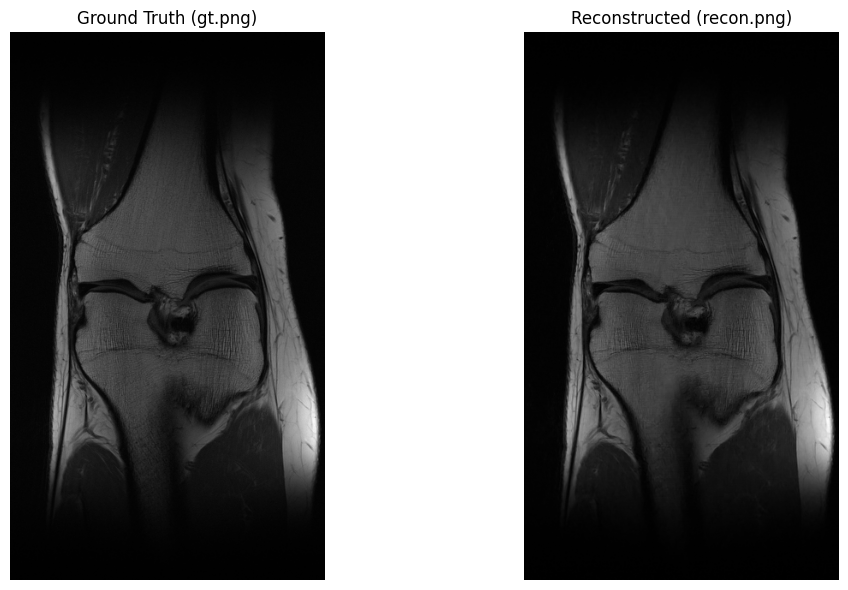

In [ ]:
import matplotlib.pyplot as plt
from skimage.io import imread

gt_path = '/content/IMJENSE/results/gt.png'
recon_path = '/content/IMJENSE/results/recon.png'

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Display Ground Truth
axes[0].imshow(imread(gt_path), cmap='gray')
axes[0].set_title('Ground Truth (gt.png)')
axes[0].axis('off')

# Display Reconstruction
axes[1].imshow(imread(recon_path), cmap='gray')
axes[1].set_title('Reconstructed (recon.png)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### 5. Conclusion and Experiment Summary

- **Model Execution**: The IMJENSE reconstruction pipeline completed successfully using the custom virtual environment on the GPU runtime.
- **Performance Metrics**:
  - **Reconstruction Time**: ~16.06 minutes
  - **Structural Similarity Index (SSIM)**: `0.94` (indicating a very high similarity to the ground truth)
  - **Peak Signal-to-Noise Ratio (PSNR)**: `40.51` dB
- **Visual Evaluation**: The reconstructed image demonstrates excellent noise reduction and preserves structural sharpness relative to the Ground Truth (`gt.png`).